# Robustness of KNN metrics


In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import matplotlib.pyplot as plt
import json
import re
import ast
import colorcet as cc
import matplotlib.font_manager as font_manager
from scipy.stats import wilcoxon
import math
from statsmodels.stats.multitest import multipletests


font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

from analysis_helpers import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [4]:
def plot_metric(metric_to_plot, df, param):
    df_filtered = df[df['Metric'] == metric_to_plot].copy()

    df_filtered[param] = df_filtered['Params'].apply(
        lambda x: int(ast.literal_eval(x)[param]) if isinstance(x, str) else float(x[param])
    )
    df_filtered = df_filtered.sort_values(param)

    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=df_filtered, 
        x=param, 
        y='Value', 
        hue='Integration', 
        marker='o',
        linewidth=1.5
    )

    plt.title(f'Integration Performance: {metric_to_plot}', fontsize=14)
    plt.xlabel('Number of Neighbors (n_neighbors)', fontsize=12)
    plt.ylabel('Metric Score', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Integration Method', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.gca().legend_.remove()

    plt.tight_layout()
    plt.show()

In [5]:
def plot_ranks(metric_to_plot, df, param):
    df_filtered = df[df['Metric'] == metric_to_plot].copy()

    df_filtered[param] = df_filtered['Params'].apply(
        lambda x: int(ast.literal_eval(x)[param]) if isinstance(x, str) else float(x[param])
    )

    df_filtered['Rank'] = df_filtered.groupby(param)['Value'].rank(ascending=False, method='min').astype(int)
    df_filtered = df_filtered.sort_values(param)

    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=df_filtered, 
        x=param, 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        linewidth=2.5
    )

    plt.gca().invert_yaxis()

    max_rank = int(df_filtered['Rank'].max())
    plt.yticks(range(1, max_rank + 1))

    plt.title(f'Integration Rank Stability across {param}', fontsize=14)
    plt.xlabel(param, fontsize=12)
    plt.ylabel('Rank (1 = Best Performance)', fontsize=12)
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend(title='Integration Method', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.gca().legend_.remove()
    
    plt.tight_layout()
    plt.show()


def plot_multiple_ranks(metrics_params_dict, df):
    """
    metrics_params_dict: {'CLISI': 'k0', 'KBET': 'k', 'LDFDIFF': 'k'}
    """
    all_data = []

    for metric, param_key in metrics_params_dict.items():
        df_m = df[df['Metric'] == metric].copy()
        if df_m.empty:
            continue
        df_m['param_value'] = df_m['Params'].apply(
            lambda x: float(ast.literal_eval(x)[param_key]) if isinstance(x, str) else float(x[param_key])
        )
        # method='min' handles ties; ascending=False makes high values Rank 1
        df_m['Rank'] = df_m.groupby('param_value')['Value'].rank(ascending=False, method='min').astype(int)
        
        all_data.append(df_m)

    plot_df = pd.concat(all_data).sort_values('param_value')

    g = sns.relplot(
        data=plot_df,
        x='param_value',
        y='Rank',
        hue='Integration',
        col='Metric',
        kind='line',
        marker='o',
        linewidth=2,
        col_wrap=3,
        facet_kws={'sharey': False, 'sharex': False},
        height=4,
        aspect=1.1
    )

    for ax in g.axes.flat:
        ax.invert_yaxis()
        y_vals = ax.get_yticks()
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(True, linestyle='--', alpha=0.4)

    g.set_axis_labels("Parameter Value", "Rank (Top is Best)")
    g.set_titles("{col_name} Stability")
    
    plt.show()

In [6]:
def plot_metrics_subplots(metrics_params_dict, df):
    """
    metrics_params_dict: {'CLISI': 'k0', 'KBET': 'k', 'LDFDIFF': 'k'}
    """
    all_data = []

    for metric, param_key in metrics_params_dict.items():
        df_m = df[df['Metric'] == metric].copy()
        if df_m.empty: continue

        df_m['param_value'] = df_m['Params'].apply(
            lambda x: float(ast.literal_eval(x)[param_key]) if isinstance(x, str) else float(x[param_key])
        )
        all_data.append(df_m)

    plot_df = pd.concat(all_data).sort_values('param_value')

    g = sns.relplot(
        data=plot_df,
        x='param_value',
        y='Value',
        hue='Integration',
        col='Metric',
        kind='line',
        marker='o',
        col_wrap=3,
        facet_kws={'sharey': False, 'sharex': False},
        height=4,
        aspect=1.2
    )

    g.set_axis_labels("Parameter Value", "Metric Score")
    g.set_titles("{col_name}")

    plt.show()

In [7]:
def compute_w_across_integrations(metrics_params_dict, df):
    all_data = []
    for metric, param_key in metrics_params_dict.items():
        df_m = df[df['Metric'] == metric].copy()
        if df_m.empty:
            continue
        df_m['param_value'] = df_m['Params'].apply(
            lambda x: float(ast.literal_eval(x)[param_key]) if isinstance(x, str) else float(x[param_key])
        )
        df_m['Rank'] = df_m.groupby('param_value')['Value'].rank(ascending=False, method='average')
        all_data.append(df_m)
    rank_df = pd.concat(all_data).sort_values('param_value')

    results = []

    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='param_value', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [8]:
def extract_numeric_param(p):
    if isinstance(p, str):
        p = ast.literal_eval(p)
    return float(list(p.values())[0])

def get_top9(df):
    df['Param_Value_Num'] = df['Params'].apply(extract_numeric_param)

    filtered_df = (
        df.sort_values('Param_Value_Num')
        .groupby(['Dataset', 'Integration', 'Metric'])
        .head(9)
    )
    filtered_df = filtered_df.drop(columns=['Param_Value_Num'])
    return filtered_df

In [9]:
params = {'ADGBD': 'n_neighbors', 'CLISI': "k0", 'ILISI': 'k0', 'KBET': "k", 'LDFDIFF': "k",
   'FKNN': 'n_neighbors', 'BKNN': 'n_neighbors', 'KBETALL': 'k',
   'RKNN': 'n_neighbors', 'AGREE': 'n_neighbors',
   'KSIM': 'k', 'BNENTROPY': 'n_neighbors', 'CNENTROPY': "n_neighbors",
   'KLDIV': "k", 'ALIGN': 'n_neighbors', 'CSMC': 'k', 'PPTPC': "n_neighbors",
   'MIX': 'k', 'PSTDB': "k", 'NNMAP': 'k', 'GC': 'k', 'CILISI': 'k0'}

In [10]:
all_dfs = []

## Collect all the data from the eight different datasets

The combined metric file is available as `robustness_knn.csv`. To reproduce the Kendall's W, instead of using the code to load the CSV files, instead subset the metric file to the given dataset. e.g.

```Python
df_full = pd.read_csv('../data/source_data/robustness_knn.csv')
df_sub = df_full[df_full['Dataset'] == 'neurips_bmmc']
```


### NeurIPS BMMC

In [11]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/neurips_bmmc/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/neurips_bmmc_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/neurips_bmmc_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/neurips_bmmc_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/neurips_bmmc_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [12]:
w_results_1 = compute_w_across_integrations(params, df)
w_results_1['Dataset'] = "neurips_bmmc"
w_results_1

,Metric,Kendall_W,Dataset
0,ADGBD,0.992847,neurips_bmmc
1,AGREE,0.994392,neurips_bmmc
2,ALIGN,0.992162,neurips_bmmc
3,BKNN,0.995709,neurips_bmmc
4,BNENTROPY,0.995996,neurips_bmmc
5,CILISI,0.936395,neurips_bmmc
6,CLISI,0.995548,neurips_bmmc
7,CNENTROPY,0.989340,neurips_bmmc
8,CSMC,0.209354,neurips_bmmc
9,FKNN,0.993725,neurips_bmmc


# Seurat PBMC

In [13]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/seurat_pbmc/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/seurat_pbmc_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/seurat_pbmc_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/seurat_pbmc_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/seurat_pbmc_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)

# CLEAR failed so remove it
df = df[df['Integration'] != 'clear-1']
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [14]:
w_results_2 = compute_w_across_integrations(params, df)
w_results_2['Dataset'] = "seurat_pbmc"
w_results_2

,Metric,Kendall_W,Dataset
0,ADGBD,0.996682,seurat_pbmc
1,AGREE,0.997591,seurat_pbmc
2,ALIGN,0.989405,seurat_pbmc
3,BKNN,0.997623,seurat_pbmc
4,BNENTROPY,0.995754,seurat_pbmc
5,CILISI,0.993390,seurat_pbmc
6,CLISI,0.988966,seurat_pbmc
7,CNENTROPY,0.995952,seurat_pbmc
8,CSMC,0.228800,seurat_pbmc
9,FKNN,0.997642,seurat_pbmc


# Human Pancreas

In [15]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pancreas/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pancreas_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pancreas_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pancreas_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pancreas_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [16]:
w_results_3 = compute_w_across_integrations(params, df)
w_results_3['Dataset'] = "human_pancreas"
w_results_3

,Metric,Kendall_W,Dataset
0,ADGBD,0.994877,human_pancreas
1,AGREE,0.990903,human_pancreas
2,ALIGN,0.993527,human_pancreas
3,BKNN,0.990008,human_pancreas
4,BNENTROPY,0.995467,human_pancreas
5,CILISI,0.995753,human_pancreas
6,CLISI,0.909430,human_pancreas
7,CNENTROPY,0.989854,human_pancreas
8,CSMC,0.491802,human_pancreas
9,FKNN,0.987599,human_pancreas


# Mouse retina

In [17]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/mouse_retina/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/mouse_retina_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/mouse_retina_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/mouse_retina_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/mouse_retina_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [18]:
w_results_4 = compute_w_across_integrations(params, df)
w_results_4['Dataset'] = "mouse_retina"
w_results_4

,Metric,Kendall_W,Dataset
0,ADGBD,0.987147,mouse_retina
1,AGREE,0.994076,mouse_retina
2,ALIGN,0.959926,mouse_retina
3,BKNN,0.992075,mouse_retina
4,BNENTROPY,0.987455,mouse_retina
5,CILISI,0.992832,mouse_retina
6,CLISI,0.856691,mouse_retina
7,CNENTROPY,0.996177,mouse_retina
8,CSMC,0.824115,mouse_retina
9,FKNN,0.996057,mouse_retina


# Cellranger versions


In [19]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/cellranger_versions/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/cellranger_versions_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/cellranger_versions_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/cellranger_versions_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/cellranger_versions_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [20]:
w_results_5 = compute_w_across_integrations(params, df)
w_results_5['Dataset'] = "cellranger_versions"
w_results_5

,Metric,Kendall_W,Dataset
0,ADGBD,0.997320,cellranger_versions
1,AGREE,0.998401,cellranger_versions
2,ALIGN,0.997574,cellranger_versions
3,BKNN,0.991386,cellranger_versions
4,BNENTROPY,0.998341,cellranger_versions
5,CILISI,0.993516,cellranger_versions
6,CLISI,0.900071,cellranger_versions
7,CNENTROPY,0.984659,cellranger_versions
8,CSMC,0.879187,cellranger_versions
9,FKNN,0.988779,cellranger_versions


# Human pbmc seq techs

In [21]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pbmc_seq_techs/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pbmc_seq_techs_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pbmc_seq_techs_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pbmc_seq_techs_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/human_pbmc_seq_techs_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [22]:
w_results_6 = compute_w_across_integrations(params, df)
w_results_6['Dataset'] = "human_pbmc_seq_techs"
w_results_6

,Metric,Kendall_W,Dataset
0,ADGBD,0.995348,human_pbmc_seq_techs
1,AGREE,0.990651,human_pbmc_seq_techs
2,ALIGN,0.991820,human_pbmc_seq_techs
3,BKNN,0.989602,human_pbmc_seq_techs
4,BNENTROPY,0.996708,human_pbmc_seq_techs
5,CILISI,0.995799,human_pbmc_seq_techs
6,CLISI,0.993467,human_pbmc_seq_techs
7,CNENTROPY,0.988128,human_pbmc_seq_techs
8,CSMC,0.377442,human_pbmc_seq_techs
9,FKNN,0.978686,human_pbmc_seq_techs


# scIB sim1

In [23]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/scib_sim1/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/scib_sim1_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/scib_sim1_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/scib_sim1_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/scib_sim1_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [24]:
w_results_7 = compute_w_across_integrations(params, df)
w_results_7['Dataset'] = "scib_sim1"
w_results_7

,Metric,Kendall_W,Dataset
0,ADGBD,0.994866,scib_sim1
1,AGREE,0.989655,scib_sim1
2,ALIGN,0.996279,scib_sim1
3,BKNN,0.995111,scib_sim1
4,BNENTROPY,0.994775,scib_sim1
5,CILISI,0.993913,scib_sim1
6,CLISI,0.888591,scib_sim1
7,CNENTROPY,0.994053,scib_sim1
8,CSMC,0.568136,scib_sim1
9,FKNN,0.987613,scib_sim1


# NPH Cerebellum

In [25]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/nph_cerebellum/metrics/all-metrics.csv')
df = df[~df.Metric.isin(['KBETALL', 'AGREE'])]
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/nph_cerebellum_gc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/nph_cerebellum_cilisi/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/nph_cerebellum_rescue/metrics/all-metrics.csv')
df5 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/knn_ablation/nph_cerebellum_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3, df4, df5])
df = df.drop_duplicates(keep='last')
df = df[~df['Params'].isna()]
df['Params'] = df['Params'].apply(ast.literal_eval)
df = get_top9(df)
all_dfs.append(df)

In [ ]:
plot_metrics_subplots(params, df)

In [ ]:
plot_multiple_ranks(params, df)

In [26]:
w_results_8 = compute_w_across_integrations(params, df)
w_results_8['Dataset'] = "nph_cerebellum"
w_results_8

,Metric,Kendall_W,Dataset
0,ADGBD,0.996844,nph_cerebellum
1,AGREE,0.990104,nph_cerebellum
2,ALIGN,0.996814,nph_cerebellum
3,BKNN,0.946734,nph_cerebellum
4,BNENTROPY,0.998646,nph_cerebellum
5,CILISI,0.987356,nph_cerebellum
6,CLISI,0.846286,nph_cerebellum
7,CNENTROPY,0.992861,nph_cerebellum
8,CSMC,0.856452,nph_cerebellum
9,FKNN,0.962356,nph_cerebellum


## Plot Kendall's W

In [27]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])

In [28]:
w_results['Metric'] = w_results['Metric'].replace({
    'CSMC': "CSMS", 'BNENTROPY': "BNENT", "CNENTROPY": "CNENT"
})

/tmp/ipykernel_2037236/2958675922.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


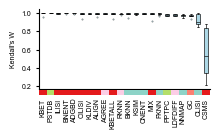

In [29]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

order = w_results.groupby("Metric")["Kendall_W"].median().sort_values(ascending=False).index

h0 = 'Clusters-as-predictions & KNN'
h1 = 'Logistic regression'
h2 = 'Cluster-label similarity'
h3 = 'Isolated labels & GC'
h4 = 'Cell types as clusters'
h5 = 'Joint bioconservation & batch correction'
h6 = 'Cluster quality 1'
h7 = 'Fine-grained biology'
h8 = 'Cluster quality 2'
k0 = 'Primarily bioconservation'
k1 = 'BASW & SV'
k2 = 'Clustering metrics'
k3 = 'PCR & PROBELR'
k5 = 'Unique metrics'
k6 = 'KNN'
metric_to_group = {
    'fmi': h2, 'awc': h2, 'ari': h2, 'vi': h2, 'nmi': h2, 'ami': h2, 'vm':h2, 
    'bari': h2, 'bami': h2, 'bvm': h2, 
    'isoasw': h3, 'gc': h3, 'isof1': h3, 'isolisi': h3,
    'casw': h4, 'cdbi': h4, 'cch': h4, 
    'blogreg': h1, 'flogreg': h1, 
    'clisi': h0, 'fknn': h0, 'ksim': h0, 'ocs': h0, 'nnmap': h0, 'cnent': h0, 
    'cnentropyw': h0, 'bknn': h0, 'f1': h0, 'mcc': h0, 'jacc': h0, 'purity': h0, 
    'ccent': h0, 'homo': h0, 'arif': h0, 'nmif': h0, 
    'clustch': h6, 'clustasw': h6, 'clustdbi': h6, 
    'comp': h5, 'pptpc': h5, 'pstdb': h5, 
    'ldfdiff': h7, 'agree': h7, 'morani': h7, 'rknn': h7, 'ccc': h7, 
    'scgraph': h7, 'corrmse': h7, 'traj': h7, 'scgraphp': h7, 'scgraphm': h7,
    'modularity': h8, 'compact': h8, 'separation': h8,
    'mix': k6, 'align': k6, 'ilisi': k6, 'bnent': k6, 'kldiv': k6,
    'adgbd': k6, 'kbetall': k6, 'cilisi': k6, 'csms': k6, 'kbet': k6,
    'bras': k5, 'embdiv': k5, 'probe': k5,  'pcr': k3,
    'probelr': k3, 'proberf': k5,
    'bp': k2, 'bcent': k2, 'cre': k2, 'batchari': k2,
    'basw': k1, 'sv': k1,
}
group_to_color = {
    h0: '#8dd3c7', h1: '#ffffb3', h2: '#bebada', h3: '#fb8072', h4: '#80b1d3',
    h6: '#fdb462', h5: '#b3de69', h7: '#fccde5', h8: '#d9d9d9',
    k6: '#e41a1c', k5: '#4daf4a', k3: '#ff7f00', k2: '#377eb8', k1: 'ffff33', k0: '#a65628'
}

boxplot_data = [w_results[w_results["Metric"] == metric]["Kendall_W"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.3, 1.1))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.tick_params(axis='x', length=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's W", fontsize=5)
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()  # finalize layout before adding patches

# --- sizing in points ---
box_h_pt   = 4    # height of each color box
box_w_pt   = 18   # width of each color box (adjust to taste)
gap_pt     = 0.6    # gap between tick line and box top

# Convert points to display units
dpi        = fig.dpi
pt_to_disp = dpi / 72.0

# Transform: x in data coords, y pinned to axes bottom in display coords
trans = ax.transData

if len(order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1  # 85% of spacing, leaving a small gap between boxes

for i, metric in enumerate(order):
    tick_x = i + 1
    grp    = metric_to_group.get(metric.lower(), "Unknown")
    color  = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    inv = ax.transAxes.inverted()
    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=5,
        rotation=90,
        clip_on=False,
    )
plt.savefig('../publication_figures/knn_W.svg', dpi=300, bbox_inches='tight')
plt.show()

### Compute coefficient of variations

In [28]:
df_full = pd.concat(all_dfs)
df_full.replace([np.inf, -np.inf], np.nan, inplace=True)

In [29]:
df_full['k'] = df_full['Params'].apply(lambda x: list(x.values())[0] if isinstance(x, dict) else None)
df_full['k'] = df_full['k'].astype(float)

In [30]:
df_full.to_csv('../results/spreadsheets/ablation_analysis_knn_metrics.csv', index=False)

In [33]:
d = {}
for metric in df_full['Metric'].unique():
    if metric == 'KLDIV' or metric == 'ALIGN': continue
    sub = df_full[df_full['Metric'] == metric]
    result = []
    for k in sub['k'].unique():
        sub2 = sub[sub['k'] == k]
        res = sub2.groupby('Dataset')['Value'].apply(lambda x: x.std() / np.abs(x.mean())).reset_index()
        res['k'] = k
        result.append(res)
    result = pd.concat(result)
    d[metric] = result

/tmp/ipykernel_63191/4083238878.py:8: RuntimeWarning: invalid value encountered in scalar divide
  res = sub2.groupby('Dataset')['Value'].apply(lambda x: x.std() / np.abs(x.mean())).reset_index()


In [34]:
d['CSMC'] = d['CSMC'].replace(np.nan, 0)

In [35]:
def plot_cv_metrics(
    data: dict,
    reference_k: dict,
    dataset_col: str = "Dataset",
    k_col: str = "k",
    value_col: str = "Value",
    ncols: int = 6,
    figsize_per_cell: tuple = (1.05, 1),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple line charts of coefficient of variation (CV) vs k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a per-metric reference k value. P-values are adjusted across all
    metric × k comparisons using the specified multiple-testing correction.
 
    Parameters
    ----------
    data : dict[str, pd.DataFrame]
        Keys are metric names. Each DataFrame must contain `dataset_col`,
        `k_col`, and `value_col` columns.
    reference_k : dict[str, scalar]
        Maps each metric name to its reference k value for significance testing.
    dataset_col : str
        Column name identifying datasets (default 'Dataset').
    k_col : str
        Column name for k values (default 'k').
    value_col : str
        Column name for CV values (default 'Value').
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    adjustment_method : str
        Multiple-testing correction passed to statsmodels multipletests
        (e.g. 'fdr_bh', 'bonferroni', 'holm'). Default is 'fdr_bh'.
    """
    metric_names = ['AGREE', 'CLISI', 'CNENTROPY', 'FKNN', 'KSIM',
                    'LDFDIFF', 'NNMAP', 'RKNN',
                    'ADGBD', 'BKNN', 'BNENTROPY', 'CILISI',
                    'CSMC', 'GC', 'ILISI', 'KBET', 'KBETALL',
                    'MIX', 'PPTPC', 'PSTDB']
    n_metrics = len(metric_names)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    # Pass 1: compute means, stderrs, and raw p-values per metric
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
    k_values_per_metric = {}
 
    for metric in metric_names:
        df = data[metric]
        ref_k = reference_k[metric]
        k_values = sorted(df[k_col].unique())
        k_values_per_metric[metric] = k_values
 
        ref_vals = df[df[k_col] == ref_k][value_col].dropna().values
 
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][value_col].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != ref_k and len(vals) >= 2 and len(ref_vals) >= 2:
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
 
    # Adjust all p-values together across all metrics and k values
    keys = list(raw_p_values.keys())
    if keys:
        raw_p_array = np.array([raw_p_values[k] for k in keys])
        _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
        adj_p_values = dict(zip(keys, adj_p_array))
    else:
        adj_p_values = {}
 
    for idx, metric in enumerate(metric_names):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
        k_values = k_values_per_metric[metric]
        ref_k = reference_k[metric]
        x = np.arange(len(k_values))
        ref_x = k_values.index(ref_k)
 
        ax.plot(x, means, color=color, linewidth=1.1, zorder=3,
                marker="o", markersize=2, markerfacecolor="white",
                markeredgecolor=color, markeredgewidth=1.8)
#         ax.fill_between(x, means - stderrs, means + stderrs,
#                         color=color, alpha=0.12, zorder=2)
        ax.axvline(ref_x, color="#888780", linewidth=1,
                   linestyle="--", zorder=1, alpha=0.7)
 
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0]
        point_offset = y_range * 0.04
 
        for i, k in enumerate(k_values):
            if k == ref_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                ax.text(x[i], means[i] + point_offset, stars, ha="center", va="bottom",
                        fontsize=7, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric.replace('CSMC', 'CSMS').replace("ENTROPY", 'ENT'), fontsize=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = (idx + ncols) >= n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel(k_col, fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(x)
        ax.set_xticklabels(k_values, rotation=90)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
        fig.canvas.draw()
 
    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)
 
    return fig

/tmp/ipykernel_63191/1811203730.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


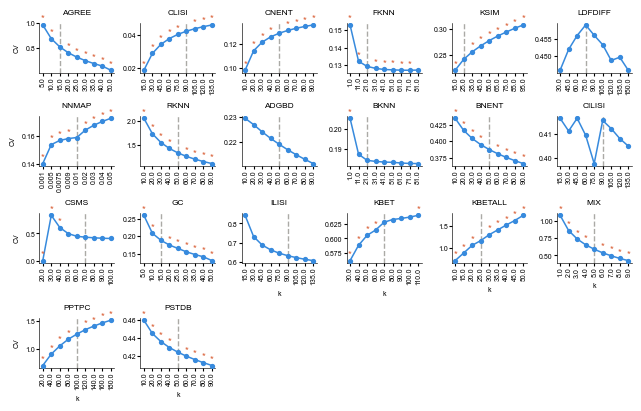

In [36]:
fig = plot_cv_metrics(d, {'ADGBD': 50, 'CLISI': 90, 'KBET': 70, 'KBETALL': 70,
                    'LDFDIFF': 75, 'FKNN': 21, 'BKNN': 21, 'RKNN': 50,
                    'AGREE': 50, 'KSIM': 25, 'BNENTROPY': 50, 'CNENTROPY': 50,
                    'MIX': 5, 'ILISI': 90, 'PPTPC': 100, 'AGREE': 15, 'KBETALL': 25,
                    'CSMC': 70, 'PSTDB': 50, 'NNMAP': 0.01, 'GC': 15, 'CILISI': 90})
# fig.savefig('../publication_figures/knn_ablation_cvs.png', dpi=300, bbox_inches='tight')
fig.show()

## Plot specific metrics

In [162]:
def plot_metrics_dataset(metrics_params_dict, df, xticks):
    """
    metrics_params_dict: {'CLISI': 'k0', 'KBET': 'k', 'LDFDIFF': 'k'}
    """
    all_data = []

    for metric, param_key in metrics_params_dict.items():
        df_m = df[df['Metric'] == metric].copy()
        df_m['param_value'] = df_m['Params'].apply(lambda x: float(ast.literal_eval(x)[param_key]) if isinstance(x, str) else float(x[param_key]))
        all_data.append(df_m)

    plot_df = pd.concat(all_data).sort_values(['Dataset', 'param_value'])

    unique_integrations = sorted(plot_df['Integration'].unique())
    glasbey_colors = cc.palette['glasbey']
    integration_palette = {
        integration: glasbey_colors[i % len(glasbey_colors)] 
        for i, integration in enumerate(unique_integrations)
    }

    unique_datasets = plot_df['Dataset'].unique()
    n_datasets = len(unique_datasets)
    n_cols = min(4, n_datasets)
    n_rows = (n_datasets + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(
        nrows=n_rows, ncols=n_cols, 
        figsize=(6.75, 3.5), 
        sharex=False, sharey=False
    )

    axes = axes.flatten() if n_datasets > 1 else [axes]
    for i, dataset in enumerate(unique_datasets):
        ax = axes[i]
        dataset_df = plot_df[plot_df['Dataset'] == dataset]
        
        sns.lineplot(
            data=dataset_df,
            x='param_value', y='Value',
            hue='Integration',
            marker='o', linewidth=.45, markersize=1, markeredgewidth=0,
            ax=ax, palette=integration_palette,
            hue_order=unique_integrations,
            legend=True if i == 0 else False 
        )
        ax.set_title(dataset, fontsize=6)
        ax.set_xlabel("k", fontsize=5)
        ax.set_ylabel(plot_df['Metric'].unique()[0], fontsize=5)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.set_xticks(xticks)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    if n_datasets > 0:
        handles, labels = axes[0].get_legend_handles_labels()
        axes[0].get_legend().remove() # Strip it from the first plot slot
        
        # Place legend globally at the bottom or top depending on column layout
        fig.legend(
            handles, labels,
            loc='lower center',
            bbox_to_anchor=(0.5, -0.15),
            ncol=8, fontsize=5, frameon=False
        )
    plt.tight_layout()
    return fig


def plot_ranks_dataset(metrics_params_dict, df, xticks):
    """
    metrics_params_dict: {'CLISI': 'k0', 'KBET': 'k', 'LDFDIFF': 'k'}
    """
    all_data = []

    for metric, param_key in metrics_params_dict.items():
        df_m = df[df['Metric'] == metric].copy()
        
        df_m['param_value'] = df_m['Params'].apply(lambda x: float(ast.literal_eval(x)[param_key]) if isinstance(x, str) else float(x[param_key]))
        df_m['Rank'] = df_m.groupby('param_value')['Value'].rank(ascending=False, method='min').astype(int)
        all_data.append(df_m)

    plot_df = pd.concat(all_data).sort_values('param_value')

    unique_integrations = sorted(plot_df['Integration'].unique())
    glasbey_colors = cc.palette['glasbey']
    integration_palette = {
        integration: glasbey_colors[i % len(glasbey_colors)] 
        for i, integration in enumerate(unique_integrations)
    }

    unique_datasets = plot_df['Dataset'].unique()
    n_datasets = len(unique_datasets)
    n_cols = min(4, n_datasets)
    n_rows = (n_datasets + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        nrows=n_rows, ncols=n_cols, 
        figsize=(6.75, 3.5), 
        sharex=False, sharey=False
    )

    axes = axes.flatten() if n_datasets > 1 else [axes]
    
    for i, dataset in enumerate(unique_datasets):
        ax = axes[i]
        metric_df = plot_df[plot_df['Dataset'] == dataset]
        
        sns.lineplot(
            data=metric_df,
            x='param_value', y='Rank',
            hue='Integration',
            marker='o', linewidth=.45, markersize=1, markeredgewidth=0,
            ax=ax, palette=integration_palette,
            hue_order=unique_integrations,
            legend=True if i == 0 else False 
        )
        
        # Formatting matching your requirements
        ax.invert_yaxis()  # Put Rank 1 at the top
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.4)
        
        ax.set_title(dataset, fontsize=6)
        ax.set_xlabel("k", fontsize=5)
        ax.set_ylabel("Rank", fontsize=5)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.set_xticks(xticks)

    # Clean up empty panels
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])


    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].get_legend().remove()

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.15),
        ncol=8, fontsize=5, frameon=False
    )
        
    plt.tight_layout()
    return fig

In [63]:
all_df = pd.concat(all_dfs)
all_df['Dataset'] = all_df['Dataset'].replace('human_pbmc_sequencing_techs', 'human_pbmc_seq_techs')
all_df['Integration'] = all_df['Integration'].str[:-2]

/tmp/ipykernel_2895476/4021105160.py:86: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values('param_value')


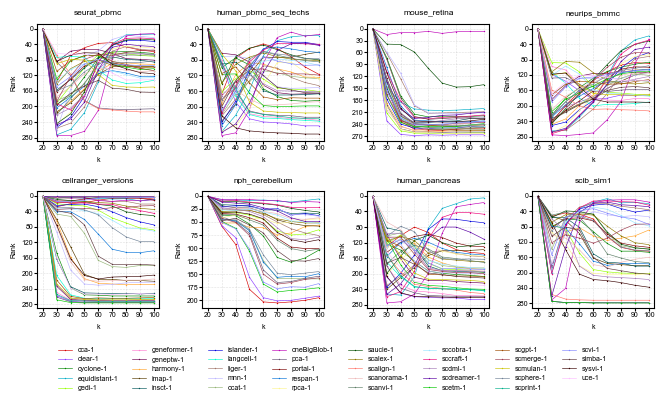

In [145]:
g = plot_ranks_dataset(params, all_df[all_df.Metric == 'CSMC'], 
                        [20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.savefig('../publication_figures/csms_ablation_k_ranks.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2895476/1037847527.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values(['Dataset', 'param_value'])


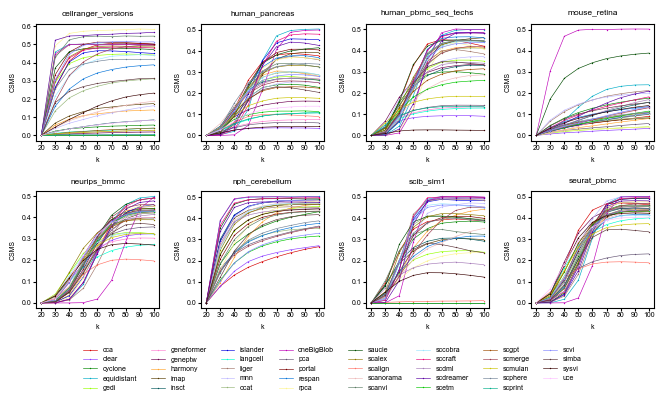

In [157]:
g = plot_metrics_dataset(params, all_df[all_df.Metric == 'CSMC'], 
                        [20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.savefig('../publication_figures/csms_ablation_k_values.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2895476/1037847527.py:86: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values(['Dataset', 'param_value'])


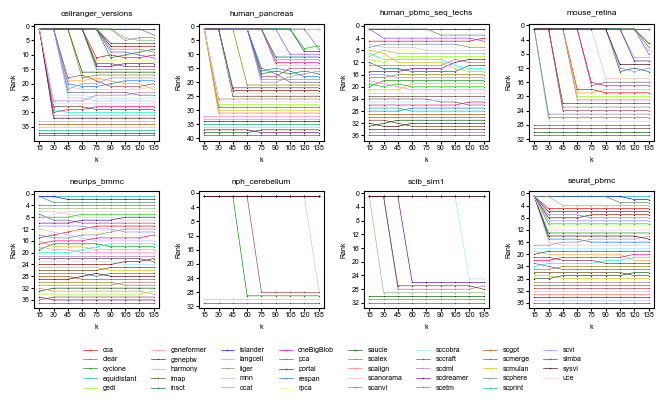

In [158]:
g = plot_ranks_dataset(params, all_df[all_df.Metric == 'CLISI'], 
                        [15, 30, 45, 60, 75, 90, 105, 120, 135])
plt.savefig('../publication_figures/clisi_ablation_k_ranks.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2895476/2031509025.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values(['Dataset', 'param_value'])


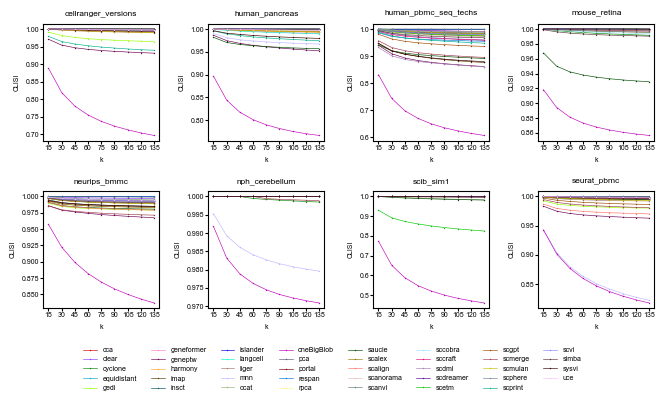

In [165]:
g = plot_metrics_dataset(params, all_df[all_df.Metric == 'CLISI'], 
                        [15, 30, 45, 60, 75, 90, 105, 120, 135])
plt.savefig('../publication_figures/clisi_ablation_k_values.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2895476/2031509025.py:86: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values('param_value')


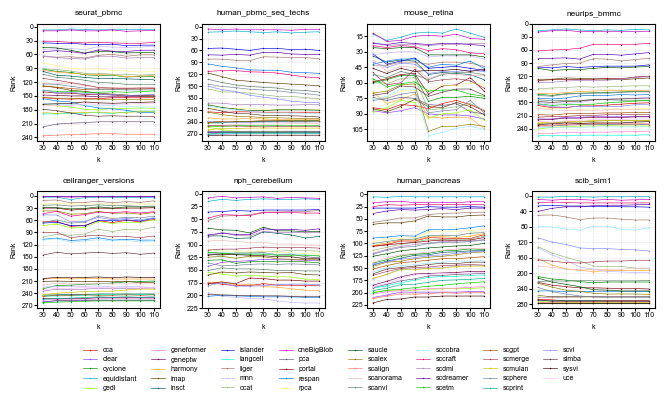

In [163]:
g = plot_ranks_dataset(params, all_df[all_df.Metric == 'KBET'], 
                        [30, 40, 50, 60, 70, 80, 90, 100, 110])
plt.savefig('../publication_figures/kbet_ablation_k_ranks.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2895476/2031509025.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plot_df = pd.concat(all_data).sort_values(['Dataset', 'param_value'])


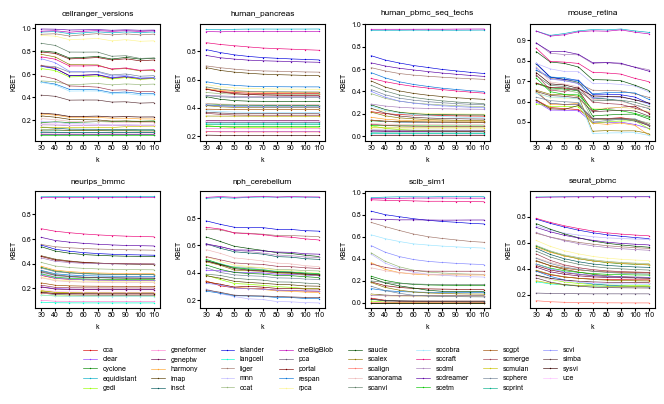

In [164]:
g = plot_metrics_dataset(params, all_df[all_df.Metric == 'KBET'], 
                        [30, 40, 50, 60, 70, 80, 90, 100, 110])
plt.savefig('../publication_figures/kbet_ablation_k_values.png', dpi=300, bbox_inches='tight')
plt.show()